# Student Academic Performance Prediction Using Deep Neural Networks

This beginner-friendly project predicts a student's final Mathematics grade (`G3`, out of 20) using the UCI Student Performance dataset. A Deep Neural Network is compared with a Random Forest baseline.

## 1. Project Introduction

The notebook loads the Mathematics data, prepares its student attributes, trains two DNN configurations and a Random Forest, evaluates them, and saves the trained artifacts for the Streamlit application.

## 2. Import Libraries

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Set a seed so the split and training are more repeatable.
np.random.seed(42)
tf.random.set_seed(42)
sns.set_style('whitegrid')

## 3. Load Dataset

In [2]:
data = pd.read_csv('student-mat.csv', sep=';')
data.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 4. Basic Dataset Understanding

In [3]:
print('Rows and columns:', data.shape)
print('Missing values:', data.isnull().sum().sum())
print('Duplicate rows:', data.duplicated().sum())

# Show column types and simple statistics.
data.info()
data.describe()

# Remove exact duplicate rows if any are found.
data = data.drop_duplicates().copy()

Rows and columns: (395, 33)
Missing values: 0
Duplicate rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null  

## 5. Data Preprocessing

`G3` is the grade we want to predict. The text columns (such as school name) are changed into 0/1 columns so the models can use them; this is called one-hot encoding. Number columns are rescaled so their values are on a similar scale. We learn the scaling from training data only, so the test data does not influence it.

In [4]:
# X contains the information used to make a prediction.
# y contains the answer we want the model to learn.
X_raw = data.drop('G3', axis=1)
y = data['G3']

numeric_columns = X_raw.select_dtypes(include=np.number).columns.tolist()
categorical_columns = X_raw.select_dtypes(exclude=np.number).columns.tolist()
print(f'Numeric features: {len(numeric_columns)}')
print(f'Categorical features: {len(categorical_columns)}')

Numeric features: 15
Categorical features: 17


## 6. Exploratory Data Analysis (EDA)

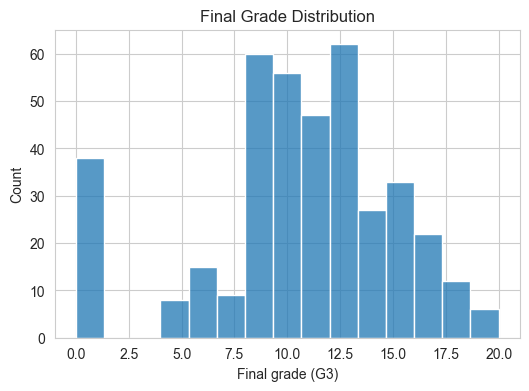

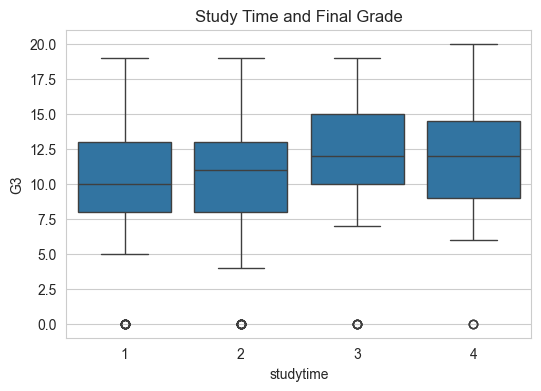

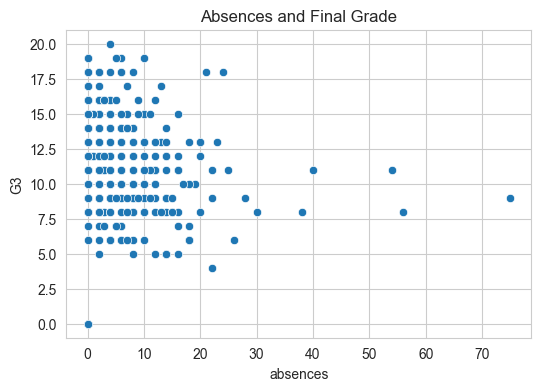

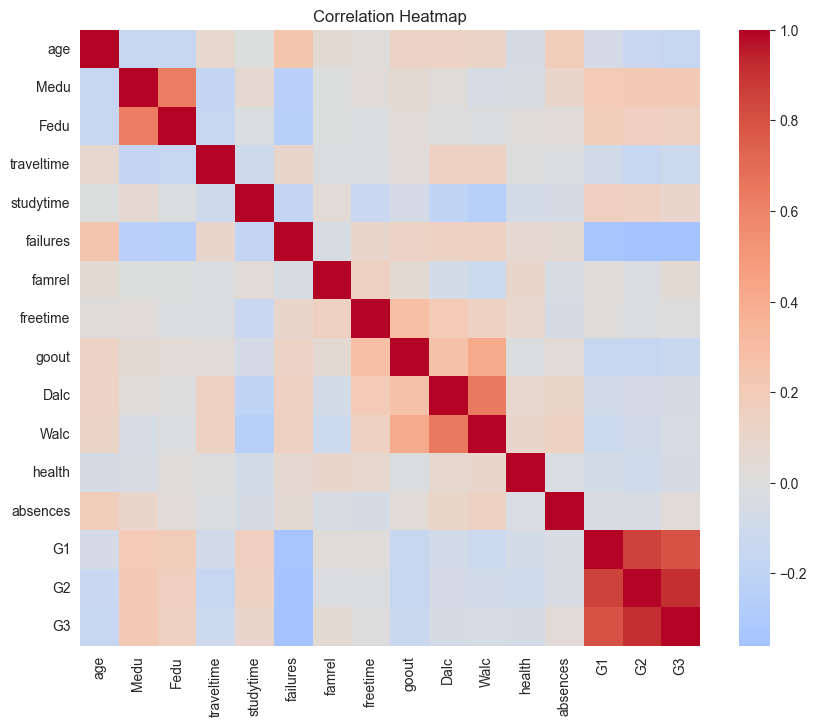

In [5]:
# 1. See how final grades are distributed.
plt.figure(figsize=(6, 4))
sns.histplot(data['G3'], bins=15)
plt.title('Final Grade Distribution')
plt.xlabel('Final grade (G3)')
plt.show()

# 2. Compare study time groups with final grades.
plt.figure(figsize=(6, 4))
sns.boxplot(data=data, x='studytime', y='G3')
plt.title('Study Time and Final Grade')
plt.show()

# 3. Compare absences with final grades.
plt.figure(figsize=(6, 4))
sns.scatterplot(data=data, x='absences', y='G3')
plt.title('Absences and Final Grade')
plt.show()

# 4. Show correlations between number-based columns.
numeric_data = data.select_dtypes(include='number')
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_data.corr(), cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.show()

## 7. Feature Selection

We look at correlations to see which number-based fields move together with `G3`. Correlation is only a clue; it does not prove that one field causes a grade to change. We keep all input fields (except `G3`) so we do not accidentally throw away useful information. The app later uses the same fields in the same order.

In [6]:
# A correlation near 1 is a strong positive relationship.
# A correlation near -1 is a strong negative relationship.
correlations = numeric_data.corr()['G3'].sort_values(ascending=False)
correlations

G3            1.000000
G2            0.904868
G1            0.801468
Medu          0.217147
Fedu          0.152457
studytime     0.097820
famrel        0.051363
absences      0.034247
freetime      0.011307
Walc         -0.051939
Dalc         -0.054660
health       -0.061335
traveltime   -0.117142
goout        -0.132791
age          -0.161579
failures     -0.360415
Name: G3, dtype: float64

## 8. Train-Test Split

We use 80% of the rows to teach the models. The other 20% is kept aside to check how well they work on rows they did not train on. The test columns are put in the same order as the training columns.

In [7]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, random_state=42
)

# One-hot encode after splitting, then align test features to the training columns.
X_train = pd.get_dummies(X_train_raw, dtype=float)
X_test = pd.get_dummies(X_test_raw, dtype=float)
# Make sure training and testing have the same columns in the same order.
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# Fit the scaler only on training numeric features.
scaler = StandardScaler()
X_train[numeric_columns] = scaler.fit_transform(X_train[numeric_columns])
X_test[numeric_columns] = scaler.transform(X_test[numeric_columns])

feature_columns = X_train.columns.tolist()
print(f'Training samples: {len(X_train)}')
print(f'Testing samples: {len(X_test)}')
print(f'Features after encoding: {len(feature_columns)}')

Training samples: 316
Testing samples: 79
Features after encoding: 58


## 9. Deep Neural Network Model

The DNN gets one row of student features as input. Its first hidden layer has 32 neurons and the second has 16. ReLU helps the network learn patterns. The final layer has one neuron, which gives the predicted grade. We use a linear output because a grade is a number, not a category.

In [8]:
# This first network has 32 neurons, then 16 neurons, then one grade output.
model_32_16 = tf.keras.Sequential()
model_32_16.add(tf.keras.layers.Input(shape=(X_train.shape[1],)))
model_32_16.add(tf.keras.layers.Dense(32, activation='relu'))
model_32_16.add(tf.keras.layers.Dense(16, activation='relu'))
model_32_16.add(tf.keras.layers.Dense(1))

model_32_16.compile(optimizer='adam', loss='mse', metrics=['mae'])
model_32_16.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         1,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,433 (9.50 KB)

 Trainable params: 2,433 (9.50 KB)

 Non-trainable params: 0 (0.00 B)

## 10. Basic Hyperparameter Tuning

We try two network sizes: 32/16 neurons and 64/32 neurons. Part of the training rows is used as validation data to help choose between them. Early stopping ends training when validation results stop improving, which helps prevent the network from memorizing the training rows.

In [9]:
# Early stopping ends training if validation error stops improving.
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=12, restore_best_weights=True
)

history_32_16 = model_32_16.fit(
    X_train, y_train, validation_split=0.20, epochs=100,
    batch_size=16, callbacks=[early_stop], verbose=0
)

# Now build and train the larger 64/32 network for comparison.
model_64_32 = tf.keras.Sequential()
model_64_32.add(tf.keras.layers.Input(shape=(X_train.shape[1],)))
model_64_32.add(tf.keras.layers.Dense(64, activation='relu'))
model_64_32.add(tf.keras.layers.Dense(32, activation='relu'))
model_64_32.add(tf.keras.layers.Dense(1))
model_64_32.compile(optimizer='adam', loss='mse', metrics=['mae'])

history_64_32 = model_64_32.fit(
    X_train, y_train, validation_split=0.20, epochs=100,
    batch_size=16, callbacks=[early_stop], verbose=0
)

# Compare the lowest validation MAE from each training run.
mae_32_16 = min(history_32_16.history['val_mae'])
mae_64_32 = min(history_64_32.history['val_mae'])
print('32/16 validation MAE:', mae_32_16)
print('64/32 validation MAE:', mae_64_32)

if mae_32_16 < mae_64_32:
    best_dnn = model_32_16
    best_dnn_name = '32/16'
else:
    best_dnn = model_64_32
    best_dnn_name = '64/32'

print('Selected DNN:', best_dnn_name)

32/16 validation MAE: 1.1601673364639282
64/32 validation MAE: 1.3783512115478516
Selected DNN: 32/16


## 11. Deep Neural Network Evaluation

In [10]:
random_forest = RandomForestRegressor(n_estimators=100, random_state=42)
random_forest.fit(X_train, y_train)
print('Random Forest training complete.')

Random Forest training complete.


## 12. DNN Results

In [11]:
# Ask each model to predict the grades for the test rows.
dnn_predictions = best_dnn.predict(X_test, verbose=0).flatten()
forest_predictions = random_forest.predict(X_test)

# Calculate the errors for the DNN.
dnn_mae = mean_absolute_error(y_test, dnn_predictions)
dnn_mse = mean_squared_error(y_test, dnn_predictions)
dnn_rmse = np.sqrt(dnn_mse)
dnn_r2 = r2_score(y_test, dnn_predictions)

# Calculate the errors for the Random Forest.
forest_mae = mean_absolute_error(y_test, forest_predictions)
forest_mse = mean_squared_error(y_test, forest_predictions)
forest_rmse = np.sqrt(forest_mse)
forest_r2 = r2_score(y_test, forest_predictions)

# Put both sets of results into a table.
evaluation_table = pd.DataFrame({
    'Model': ['DNN (' + best_dnn_name + ')', 'Random Forest'],
    'MAE': [dnn_mae, forest_mae],
    'MSE': [dnn_mse, forest_mse],
    'RMSE': [dnn_rmse, forest_rmse],
    'R2 Score': [dnn_r2, forest_r2]
})
evaluation_table.round(3)

,Model,MAE,MSE,RMSE,R2 Score
0,DNN (32/16),1.798,7.435,2.727,0.637
1,Random Forest,1.214,4.035,2.009,0.803


## 13. DNN Evaluation Chart

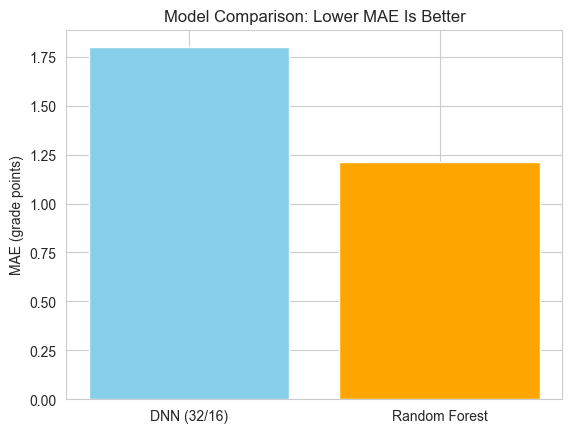

In [12]:
# Compare MAE. A shorter bar means a smaller average prediction error.
plt.bar(evaluation_table['Model'], evaluation_table['MAE'], color=['skyblue', 'orange'])
plt.ylabel('MAE (grade points)')
plt.title('Model Comparison: Lower MAE Is Better')
plt.show()

## 14. Using the DNN in the App

The Streamlit app trains the DNN from `student-mat.csv` when it starts. It does not use or save model files.

In [13]:
best_dnn.save('dnn_model.keras')
# Save the information that the app needs to prepare new student details.
categorical_options = {}
for column in categorical_columns:
    categorical_options[column] = sorted(X_raw[column].unique())

defaults = {}
for column in X_raw.columns:
    if column in numeric_columns:
        defaults[column] = X_raw[column].median()
    else:
        defaults[column] = X_raw[column].mode()[0]

feature_metadata = {
    'model_columns': feature_columns,
    'raw_columns': X_raw.columns.tolist(),
    'numeric_columns': numeric_columns,
    'categorical_columns': categorical_columns,
    'categorical_options': categorical_options,
    'defaults': defaults
}
artifacts = {
    'random_forest': random_forest,
    'scaler': scaler,
    'metadata': feature_metadata,
}
with open('artifacts.pkl', 'wb') as artifacts_file:
    pickle.dump(artifacts, artifacts_file)

print('Saved dnn_model.keras')
print('Saved artifacts.pkl')

Saved dnn_model.keras
Saved artifacts.pkl


## 15. Conclusion

The selected DNN was trained using the training rows and checked using held-out test rows. The Streamlit app trains its own DNN when it starts.